# Clasificación de imágenes con aprendizaje semisupervisado y activo

**Objetivo:** clasificar fragmentos de imágenes en 5 conceptos (Basura, Agua, Suelo, Vegetación y Ruido) etiquetando manualmente muy pocas imágenes.

**1. Recorte.** Corté cada imagen en 12 fragmentos (3 columnas × 4 filas) para tener más muestras y escenas más simples.

In [10]:
import os
from PIL import Image
from tqdm import tqdm

DATA_ROOT = "DATA"           
OUTPUT_ROOT = "DATA_12_CORTES" 

lista_rutas = []
for raiz, _, archivos in os.walk(DATA_ROOT):
    for file in archivos:
        if file.lower().endswith(('.png', '.jpg', '.jpeg')):
            lista_rutas.append((raiz, file))

print(f"Se encontraron {len(lista_rutas)} imágenes. Iniciando corte en 24 partes (6x4)...")

# 2. Procesar y cortar cada imagen
for raiz, file in tqdm(lista_rutas, desc="Cortando imágenes"):
    path_original = os.path.join(raiz, file)
    
    # Replicar la estructura de carpetas original en el destino
    carpeta_destino = raiz.replace(DATA_ROOT, OUTPUT_ROOT, 1)
    os.makedirs(carpeta_destino, exist_ok=True)
    
    try:
        with Image.open(path_original) as img:
            ancho, alto = img.size
            
            # Ajuste exacto para 12 cortes totales
            columnas = 3
            filas = 4
            
            # Tamaño de los bloques calculado dinámicamente para esta imagen
            ancho_trozo = ancho // columnas
            alto_trozo = alto // filas
                
            nombre_base, ext = os.path.splitext(file)
            contador = 1
            
            # Bucle para realizar los 24 cortes exactos
            for fila in range(filas):
                for col in range(columnas):
                    # Coordenadas de recorte
                    izq = col * ancho_trozo
                    sup = fila * alto_trozo
                    der = izq + ancho_trozo
                    inf = sup + alto_trozo
                    
                    # Ajuste fino de bordes extremos para evitar pérdida de píxeles por redondeo
                    if col == (columnas - 1): der = ancho
                    if fila == (filas - 1): inf = alto
                    
                    # Cortar el fragmento y guardarlo
                    trozo = img.crop((izq, sup, der, inf))
                    nombre_salida = f"{nombre_base}_corte_{contador}{ext}"
                    trozo.save(os.path.join(carpeta_destino, nombre_salida))
                    
                    contador += 1
    except Exception as e:
        # Si encuentra un archivo corrupto lo salta para no interrumpir el proceso
        continue

print(f"\n¡Proceso terminado con éxito! Todos los recortes de 12 partes están en: '{OUTPUT_ROOT}'")



Se encontraron 1281 imágenes. Iniciando corte en 24 partes (6x4)...


Cortando imágenes: 100%|██████████| 1281/1281 [02:34<00:00,  8.29it/s]



¡Proceso terminado con éxito! Todos los recortes de 12 partes están en: 'DATA_12_CORTES'


In [11]:
import os
import cv2
import numpy as np
from tqdm import tqdm 
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans

**2. Preprocesamiento.** Redimensioné todos los fragmentos a 128×128, los pasé de BGR a RGB y los aplané en vectores de 49 152 valores.

In [12]:
DATA_ROOT = "DATA_12_CORTES"          
IMG_SIZE = 128

X = []

lista_rutas = []
for raiz, _, archivos in os.walk(DATA_ROOT):
    for file in archivos:
        lista_rutas.append(os.path.join(raiz, file))


for path in tqdm(lista_rutas, desc="Procesando imágenes"):
    img = cv2.imread(path)
    
    if img is not None:
        img = cv2.resize(img, (IMG_SIZE, IMG_SIZE))
        img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
        #img = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
        img = img.flatten()
        
        X.append(img)

X = np.array(X)
print("Shape X ", X.shape)

Procesando imágenes: 100%|██████████| 15303/15303 [02:16<00:00, 111.98it/s]


Shape X  (15207, 49152)


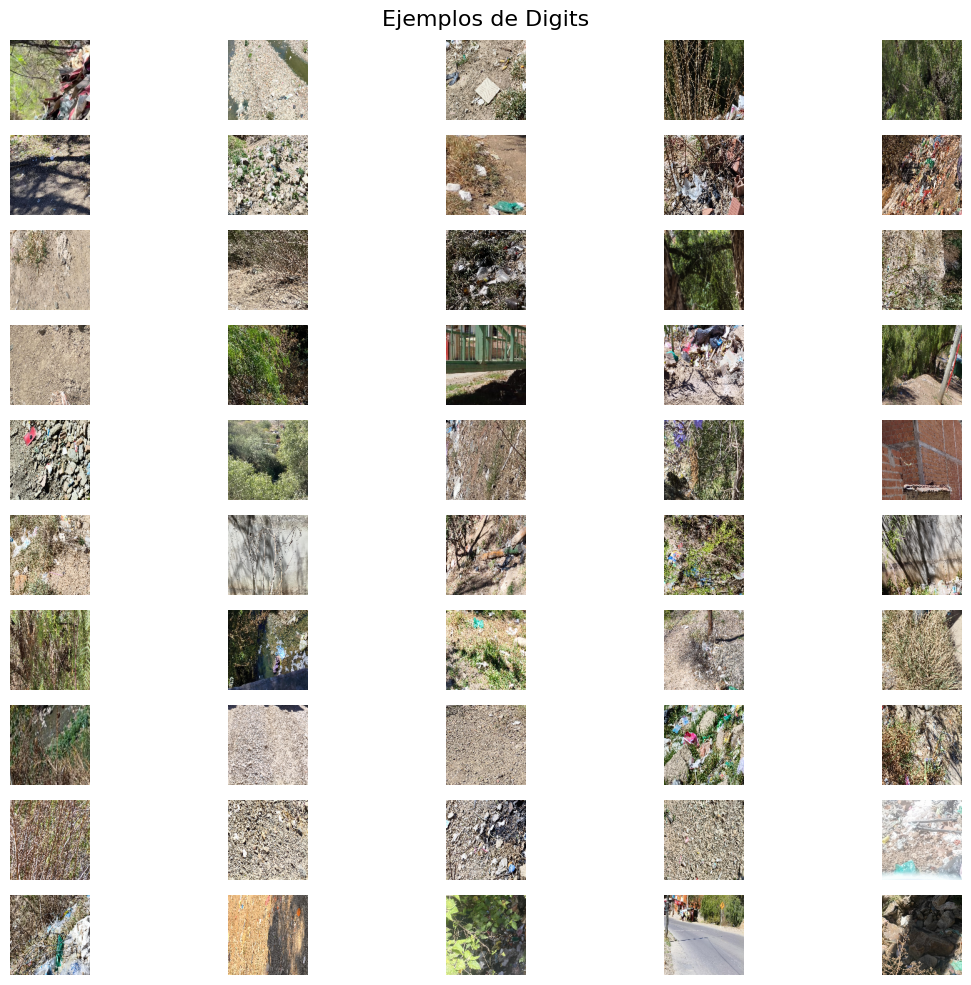

In [13]:
ind = np.random.choice(len(X),size=50,replace=False)

X_muestra = X[ind]

plt.figure(figsize=(12,10)) 

for i,img in enumerate(X_muestra):
    plt.subplot(10,5, i + 1) 

    plt.imshow(img.reshape(IMG_SIZE,IMG_SIZE,3)) 
    plt.axis('off')

plt.suptitle("Ejemplos de Digits", fontsize=16, y=0.98)
plt.tight_layout()
plt.show()

**3. División de los datos.** Separé 100 imágenes para prueba (test), 20 para validación y el resto para entrenamiento.

In [18]:
from sklearn.model_selection import train_test_split

X_resto, X_test = train_test_split(X, test_size=100, random_state=42)

X_train, X_val = train_test_split(X_resto, test_size=20, random_state=42)

del X_resto

**4. Parte no supervisada: K-Means (K = 55).** Agrupé las imágenes de entrenamiento por similitud visual, sin usar etiquetas. Usé más clústeres que clases para que cada grupo fuera más homogéneo.

In [22]:
from sklearn.cluster import MiniBatchKMeans
K=55
# kmeans = MiniBatchKMeans(n_clusters=K, batch_size=512, random_state=42)
kmeans = KMeans(n_clusters=K,random_state=42)
X_digits_dist = kmeans.fit_transform(X_train)
print(X_digits_dist.shape)
print(X_digits_dist)

(15087, 55)
[[14680.12529258 20048.64252262 16731.29561479 ... 21687.76062668
  18018.29005274 22897.20930594]
 [15060.30451205 21940.13728307 16142.81220736 ... 21942.20499403
  17781.19097261 24191.7678767 ]
 [15633.57516541 22730.74802993 17873.28802128 ... 21940.68298846
  17448.33378027 25197.71082857]
 ...
 [14813.97277197 19066.88605934 13376.24445653 ... 22186.68492587
  20016.74371167 21375.28949512]
 [18099.044768   21176.13907208 13903.22815032 ... 25292.25316179
  23354.40927634 20025.58540967]
 [18209.62686026 22965.0164816  19302.9047322  ... 24037.65179879
  22030.04734495 26158.80408199]]


**5. Aprendizaje activo (1ª ronda).** En lugar de etiquetar al azar, elegí de cada clúster la imagen más cercana al centroide, que es la más representativa. Así solo hay que etiquetar 55 imágenes.

In [23]:
idx=np.argmin(X_digits_dist,axis=0)
X_repre_d=X_train[idx]
print(X_repre_d.shape)

(55, 49152)


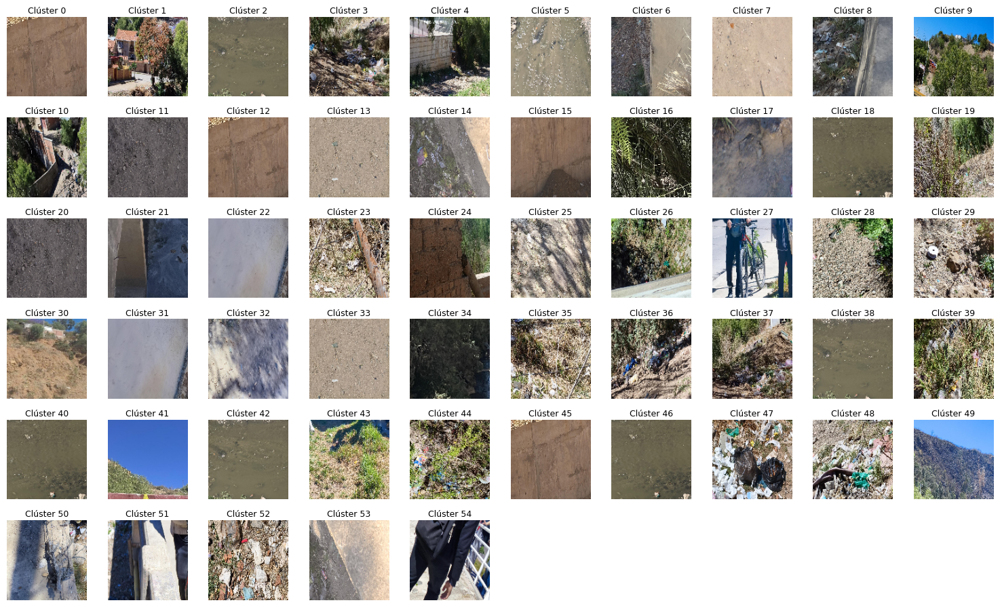

In [24]:
plt.figure(figsize=(15,15))
for index, imag in enumerate(X_repre_d):
    plt.subplot(10,10, index + 1)
    plt.imshow(imag.reshape(IMG_SIZE, IMG_SIZE,3))
    plt.title(f"Clúster {index}", fontsize=9,pad=4)
    plt.axis('off')
plt.tight_layout()
plt.show()

**6. Etiquetado manual.** Observé las 55 imágenes representativas y asigné a cada una un concepto:

• 0: Basura
• 1: Agua
• 2: Suelo
• 3: Vegetación
• 4: Ruido

In [109]:
y_repre_d = np.array([4, 3, 1, 0, 4, 1, 4, 2, 0, 3,  
                      4, 2, 4, 2, 0, 4, 3, 4, 1, 3,  
                      4, 4, 4, 2, 2, 2, 4, 4, 3, 0,  
                      2, 4, 4, 2, 3, 3, 0, 0, 1, 0, 
                      1, 4, 1, 3, 0, 4, 1, 0, 0, 3,  
                      4, 4, 0, 2, 4                 
                    ])

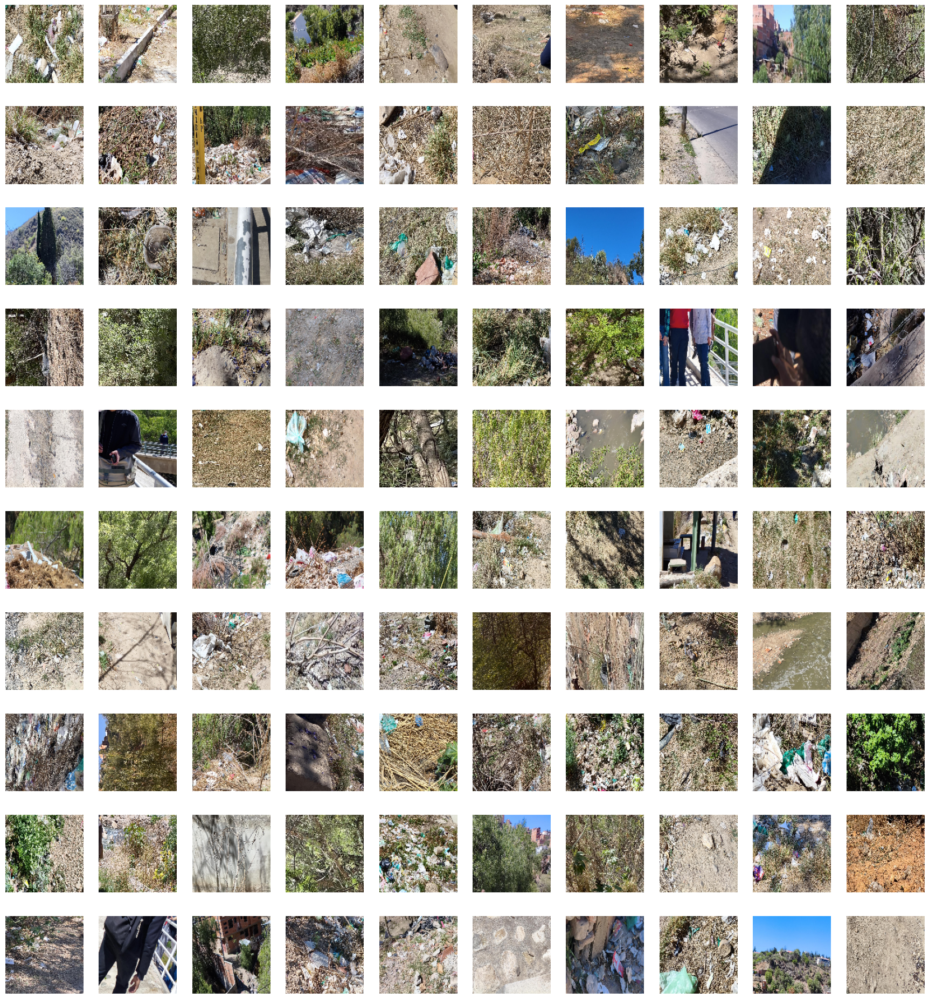

In [37]:
plt.figure(figsize=(22, 24))
for index, imag in enumerate(X_test):
    plt.subplot(10,10 , index + 1)
    plt.imshow(imag.reshape(IMG_SIZE, IMG_SIZE,3))
    plt.axis('off')
plt.show()


In [110]:
y_test= np.array([
    0, 0, 3, 3, 2, 2, 2, 0, 4, 3,  
    0, 0, 0, 0, 0, 3, 0, 4, 3, 3,  
    3, 0, 4, 0, 0, 0, 4, 0, 0, 3, 
    2, 3, 2, 2, 0, 3, 3, 4, 4, 0,
    2, 4, 2, 0, 3, 3, 1, 0, 3, 1,
    0, 3, 0, 0, 3, 0, 2, 4, 2, 0,
    2, 2, 0, 0, 0, 3, 2, 2, 1, 2,
    0, 3, 0, 0, 0, 0, 0, 0, 0, 3,  
    3, 3, 4, 3, 0, 3, 3, 2, 0, 2, 
    0, 4, 4, 0, 0, 2, 0, 0, 3, 2   
])

In [41]:
import os
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split

**7. Clasificador.** Red neuronal en PyTorch: Linear → BatchNorm → ReLU → Dropout → Linear (5 salidas), entrenada con Adam y entropía cruzada. Se guarda el mejor modelo según el accuracy en test.

In [194]:
class Dataset(torch.utils.data.Dataset):
    def __init__(self, X, Y):
        self.X = torch.from_numpy(X).float()
        self.Y = torch.from_numpy(Y).long()
    def __len__(self):
        return len(self.X)
    def __getitem__(self, ix):
        x = self.X[ix].clone() 
        x = x / 255.0
        return x, self.Y[ix]

dataset = {
    'train': Dataset(X_repre_d, y_repre_d),
    'test': Dataset(X_test, y_test),
}

dataloader = {
    'train': torch.utils.data.DataLoader(dataset['train'], batch_size=4, shuffle=True),
    'test': torch.utils.data.DataLoader(dataset['test'], batch_size=16, shuffle=False)
}

len(dataset['train']), len(dataset['test'])

(55, 100)

In [195]:
from sklearn.metrics import accuracy_score

def softmax(x):
    return torch.exp(x) / torch.exp(x).sum(axis=-1,keepdims=True)

def build_model(D_in,H,D_out,p=0.3):
    return torch.nn.Sequential(
    
        torch.nn.Linear(D_in, H),
        torch.nn.BatchNorm1d(H),
        torch.nn.ReLU(),
        torch.nn.Dropout(p),        
        torch.nn.Linear(H, D_out)
    )

def fit(model, dataloader, epochs=100, log_each=10, weight_decay=0, early_stopping=0):
    
    optimizer = torch.optim.Adam(model.parameters(), lr=0.0001, weight_decay=weight_decay)
    criterion = torch.nn.CrossEntropyLoss()
    
    l, acc = [], []
    test_l, test_acc = [], []
    best_acc, step = 0, 0
    
    for e in range(1, epochs+1):
        _l, _acc = [], []
        model.train()
        for x_b, y_b in dataloader['train']:
            y_pred = model(x_b)
            loss = criterion(y_pred, y_b)
            _l.append(loss.item())
            optimizer.zero_grad()
            loss.backward()
            optimizer.step()
            y_probas = torch.argmax(softmax(y_pred), axis=1)
            _acc.append(accuracy_score(y_b.cpu().numpy(), y_probas.cpu().detach().numpy()))
        l.append(np.mean(_l))
        acc.append(np.mean(_acc))
    
        model.eval()
        _l, _acc = [], []
        with torch.no_grad():
            for x_b, y_b in dataloader['test']:
                y_pred = model(x_b)
                loss = criterion(y_pred, y_b)
                _l.append(loss.item())
                y_probas = torch.argmax(softmax(y_pred), axis=1)
                _acc.append(accuracy_score(y_b.cpu().numpy(), y_probas.cpu().numpy()))
        test_l.append(np.mean(_l))
        test_acc.append(np.mean(_acc))
       
        if test_acc[-1] > best_acc:
            best_acc = test_acc[-1]
            torch.save(model.state_dict(), '1p.pt')
            step = 0
            print(f"Mejor modelo guardado con acc {best_acc:.5f} en epoch {e}")
        step += 1
    
        if early_stopping and step > early_stopping:
            print(f"Entrenamiento detenido en epoch {e} por no mejorar en {early_stopping} epochs seguidas")
            break
        if not e % log_each:
            print(f"Epoch {e}/{epochs} loss {l[-1]:.5f} acc {acc[-1]:.5f} test_loss {test_l[-1]:.5f} test_acc {test_acc[-1]:.5f}")
   
    model.load_state_dict(torch.load('1p.pt'))
    return {'epoch': list(range(1, len(l)+1)), 'loss': l, 'acc': acc, 'test_loss': test_l, 'test_acc': test_acc}

**8. Entrenamiento con solo las 55 imágenes etiquetadas.** Es el punto de partida (*baseline*). Resultado: **accuracy en test = 0.54**.

In [196]:
D_in=X_repre_d.shape[1]
H=100
D_out=len(np.unique(y_repre_d))

model = build_model(D_in, H, D_out, p=0.5)
hist_adam = fit(model, dataloader,epochs=100,
                log_each=10 ,weight_decay=0.0001, early_stopping=15)
print(model)

Mejor modelo guardado con acc 0.03571 en epoch 1
Mejor modelo guardado con acc 0.36607 en epoch 2
Mejor modelo guardado con acc 0.50893 en epoch 4
Epoch 10/100 loss 1.03026 acc 0.67857 test_loss 1.47614 test_acc 0.39286
Entrenamiento detenido en epoch 19 por no mejorar en 15 epochs seguidas
Sequential(
  (0): Linear(in_features=49152, out_features=100, bias=True)
  (1): BatchNorm1d(100, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
  (2): ReLU()
  (3): Dropout(p=0.5, inplace=False)
  (4): Linear(in_features=100, out_features=5, bias=True)
)


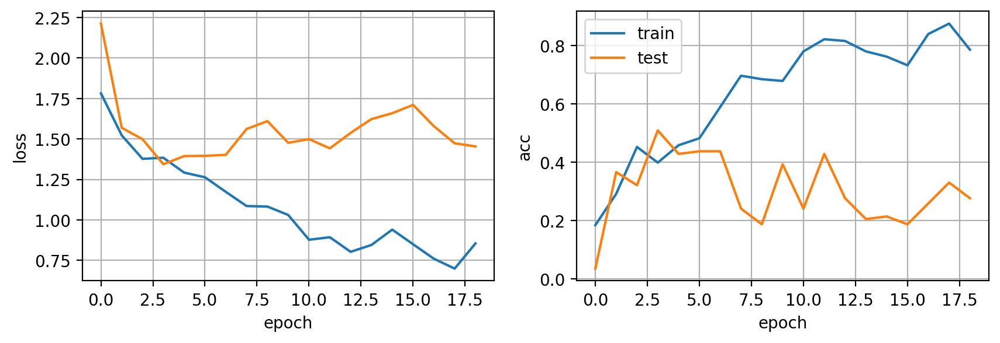

In [197]:
fig = plt.figure(dpi=200, figsize=(10,3))
ax = plt.subplot(121)
ax.plot(hist_adam['loss'])
ax.plot(hist_adam['test_loss'])
ax.grid(True)
ax.set_xlabel('epoch')
ax.set_ylabel('loss')
ax = plt.subplot(122)
ax.plot(hist_adam['acc'],label='train')
ax.plot(hist_adam['test_acc'],label='test')
ax.grid(True)
ax.set_ylabel('acc')
ax.set_xlabel('epoch')
ax.legend() 
plt.show()

In [200]:
def evaluate(model, val_loader):
    model.eval()
    lista_predicciones = []
    with torch.no_grad():
        for x_b, _ in val_loader:
            x_b = x_b.float()
            outputs = model(x_b)
            _, preds = torch.max(outputs, dim=1)
        
            lista_predicciones.append(preds.cpu().numpy())

    predicciones_finales = np.concatenate(lista_predicciones)
    
    
    return predicciones_finales.astype(int)


In [201]:
y_pred = evaluate(model, dataloader['test'])
from sklearn.metrics import accuracy_score
accuracy_score(y_test, y_pred)

0.54

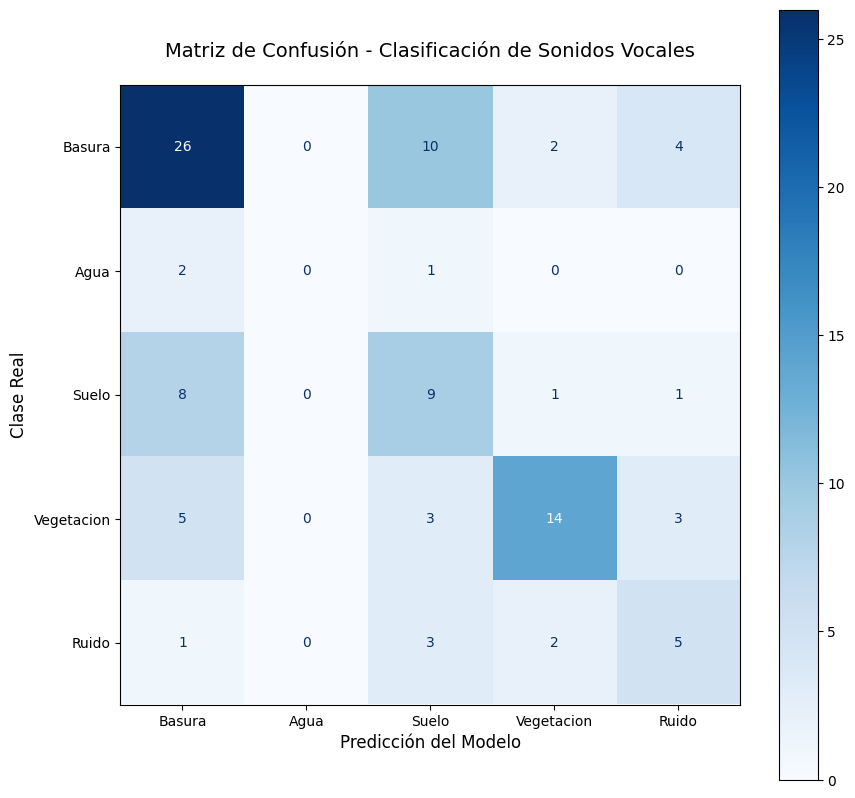

In [202]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
cm = confusion_matrix(y_test, y_pred)
nombres_clases = ["Basura", "Agua", "Suelo", "Vegetacion", "Ruido"]
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=nombres_clases)
fig, ax = plt.subplots(figsize=(10, 10)) 
disp.plot(cmap=plt.cm.Blues, ax=ax, values_format='d') 

plt.title('Matriz de Confusión - Clasificación de Sonidos Vocales', fontsize=14, pad=20)
plt.xlabel('Predicción del Modelo', fontsize=12)
plt.ylabel('Clase Real', fontsize=12)
plt.show()

**9. Parte semisupervisada: propagación de etiquetas.** Cada imagen de entrenamiento hereda el concepto de su clúster. Con 55 etiquetas manuales etiqueté todo `X_train`, combinando pocos datos etiquetados con muchos sin etiquetar. Resultado: **accuracy en test = 0.23**.

In [203]:
y_propag = np.empty(len(X_train))
for i in range(K):
  y_propag[kmeans.labels_==i] = y_repre_d[i]
print(y_propag)

[4. 2. 1. ... 1. 2. 4.]


In [204]:
dataset = {
    'train': Dataset(X_train, y_propag),
    'test': Dataset(X_test, y_test),
}

dataloader = {
    'train': torch.utils.data.DataLoader(dataset['train'], batch_size=128, shuffle=True),
    'test': torch.utils.data.DataLoader(dataset['test'], batch_size=16, shuffle=False)
}

len(dataset['train']), len(dataset['test'])

(15087, 100)

In [205]:
D_in=X_repre_d.shape[1]
H=100
D_out=len(np.unique(y_repre_d))

model = build_model(D_in, H, D_out, p=0.5)
hist_adam = fit(model, dataloader,epochs=100,
                log_each=10 ,weight_decay=0.0001, early_stopping=15)
print(model)

Mejor modelo guardado con acc 0.17857 en epoch 1
Mejor modelo guardado con acc 0.21429 en epoch 2
Epoch 10/100 loss 0.14244 acc 0.97984 test_loss 4.56004 test_acc 0.13393
Mejor modelo guardado con acc 0.23214 en epoch 13
Epoch 20/100 loss 0.06059 acc 0.99153 test_loss 4.66040 test_acc 0.09821
Entrenamiento detenido en epoch 28 por no mejorar en 15 epochs seguidas
Sequential(
  (0): Linear(in_features=49152, out_features=100, bias=True)
  (1): BatchNorm1d(100, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
  (2): ReLU()
  (3): Dropout(p=0.5, inplace=False)
  (4): Linear(in_features=100, out_features=5, bias=True)
)


In [206]:
y_pred = evaluate(model, dataloader['test'])
from sklearn.metrics import accuracy_score
accuracy_score(y_test, y_pred)

0.23

**10. Aprendizaje activo (2ª ronda): muestreo por incertidumbre.** Usé el modelo para predecir sobre `X_train` y tomé las 100 imágenes donde tuvo menor confianza (las más dudosas). Las etiqueté a mano y corregí con ellas las etiquetas propagadas.

In [207]:
model.eval()
probas_list = []

dataloader_train_ordenado = torch.utils.data.DataLoader(
    dataset['train'], batch_size=128, shuffle=False
)

with torch.no_grad():
    for x_b, _ in dataloader_train_ordenado:
        # Si usas GPU, descomenta la siguiente línea:
        # x_b = x_b.to(device)
        
        # Obtener predicciones crudas y convertirlas a probabilidades
        y_pred = model(x_b)
        p = torch.softmax(y_pred, dim=1)
        
        # Guardar en la lista como array de NumPy
        probas_list.append(p.cpu().numpy())

# 2. EQUIVALENTE A: probas = log_reg3.predict_proba(X_train)
probas = np.vstack(probas_list)

# 3. EQUIVALENTE A: confid = np.max(probas, axis=1)
confid = np.max(probas, axis=1)

# 4. EQUIVALENTE A: sorted_ixs = np.argsort(confid)
sorted_ixs = np.argsort(confid)

print("Forma de probas:", probas.shape)   
print("Índices ordenados por menor confianza:", sorted_ixs)
print(confid[sorted_ixs[:50]])

Forma de probas: (15087, 5)
Índices ordenados por menor confianza: [ 3424  4502  2531 ...  9652  2105 12160]
[0.31320074 0.31341517 0.32578886 0.32702476 0.32852662 0.33068764
 0.33710402 0.33746308 0.3411282  0.3411282  0.3432439  0.3446931
 0.3450891  0.34722385 0.34770608 0.35247946 0.3527498  0.3545155
 0.35636854 0.35975727 0.3656206  0.3675352  0.3688977  0.3781462
 0.37898442 0.37898442 0.37898442 0.3801598  0.38140237 0.38142025
 0.3815985  0.3817714  0.38580254 0.38582432 0.3874073  0.38787073
 0.38836667 0.388609   0.38943937 0.39362568 0.39655352 0.39961424
 0.39994377 0.40075076 0.40159962 0.4044591  0.40509272 0.40526477
 0.40593827 0.40707383]


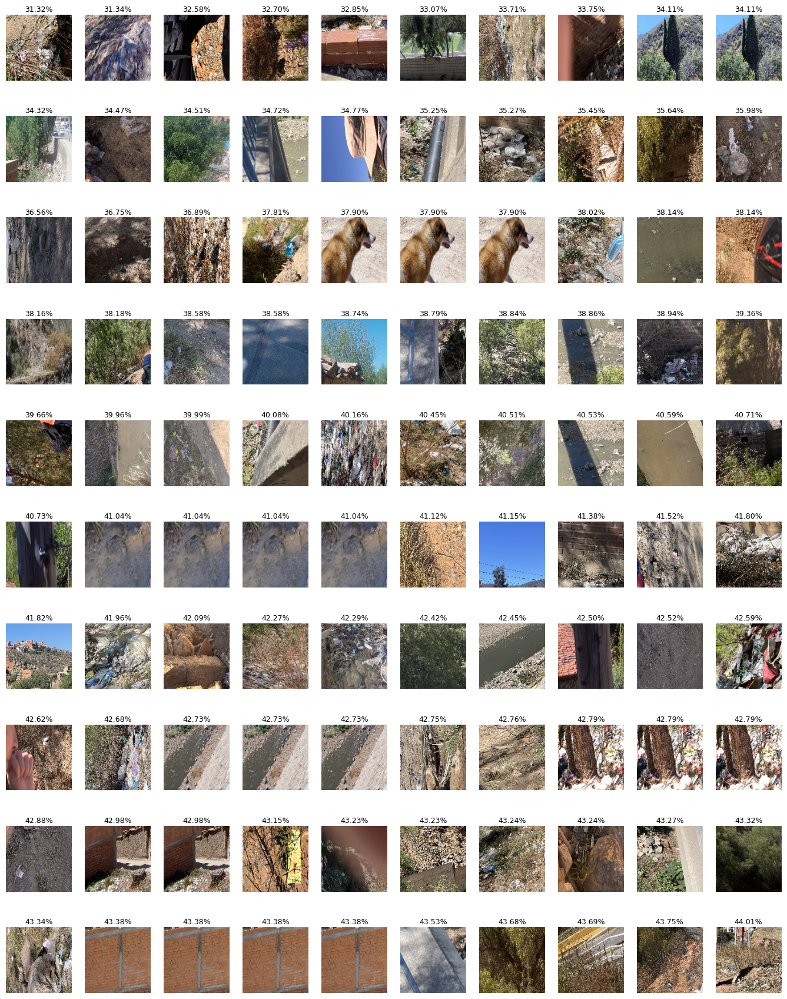

In [208]:
X_lowest = X_train[sorted_ixs[:100]]
plt.figure(figsize=(17,22))
for index, img in enumerate(X_lowest):
    confianza = confid[sorted_ixs[index]]
    plt.subplot(10,10, index + 1)
    plt.imshow(img.reshape(IMG_SIZE, IMG_SIZE,3))
    plt.title(f"{confianza:.2%}", fontsize=9,pad=4)
    plt.axis('off')
plt.show()


In [209]:
y_menor_confianza = np.array([
    3, 4, 4, 3, 4, 1, 1, 4, 3, 3,  
    3, 3, 3, 4, 4, 1, 1, 4, 3, 3,  
    4, 2, 3, 3, 4, 4, 4, 3, 3, 2,  
    2, 3, 2, 4, 4, 4, 1, 4, 3, 3,  
    3, 3, 3, 3, 0, 2, 2, 1, 1, 4,  
    4, 2, 2, 2, 2, 2, 4, 4, 2, 2,  
    2, 3, 2, 2, 2, 3, 4, 4, 2, 3,  
    4, 0, 2, 2, 2, 2, 2, 3, 3, 3,  
    4, 4, 4, 3, 2, 2, 2, 4, 3, 3,  
    4, 4, 4, 4, 4, 4, 2, 2, 3, 2   
])

In [210]:
y_lowest = y_propag.copy()
y_lowest[sorted_ixs[:100]]=y_menor_confianza

**11. Reentrenamiento con las etiquetas corregidas.** Resultado: **accuracy en test = 0.22**.

In [211]:
dataset = {
    'train': Dataset(X_train, y_lowest),
    'test': Dataset(X_test, y_test),
}

dataloader = {
    'train': torch.utils.data.DataLoader(dataset['train'], batch_size=128, shuffle=True),
    'test': torch.utils.data.DataLoader(dataset['test'], batch_size=16, shuffle=False)
}

len(dataset['train']), len(dataset['test'])

(15087, 100)

In [212]:
D_in=X_train.shape[1]
H=100
D_out=len(np.unique(y_lowest))

model = build_model(D_in, H, D_out, p=0.5)
hist_adam = fit(model, dataloader,epochs=100,
                log_each=10 ,weight_decay=0.0001, early_stopping=15)
print(model)

Mejor modelo guardado con acc 0.16964 en epoch 1
Mejor modelo guardado con acc 0.19643 en epoch 5
Mejor modelo guardado con acc 0.20536 en epoch 8
Epoch 10/100 loss 0.13028 acc 0.98155 test_loss 3.56145 test_acc 0.18750
Mejor modelo guardado con acc 0.22321 en epoch 13
Epoch 20/100 loss 0.04033 acc 0.99669 test_loss 6.38194 test_acc 0.17857
Entrenamiento detenido en epoch 28 por no mejorar en 15 epochs seguidas
Sequential(
  (0): Linear(in_features=49152, out_features=100, bias=True)
  (1): BatchNorm1d(100, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
  (2): ReLU()
  (3): Dropout(p=0.5, inplace=False)
  (4): Linear(in_features=100, out_features=5, bias=True)
)


In [220]:
y_pred = evaluate(model, dataloader['test'])
from sklearn.metrics import accuracy_score
accuracy_score(y_test, y_pred)

0.22